Shape: (100, 20)

Data Types:
 Date                  object
Order ID              object
Customer ID           object
Product ID            object
Product Category      object
Product Name          object
Quantity Sold          int64
Unit Price           float64
Discount (%)           int64
Payment Method        object
Customer Location     object
Order Status          object
Shipping Cost        float64
Profit Margin        float64
Customer Age           int64
Customer Gender       object
Customer Segment      object
Review Rating          int64
Total Sales          float64
Discounted Price     float64
dtype: object

Missing Values:
 Date                 0
Order ID             0
Customer ID          0
Product ID           0
Product Category     0
Product Name         0
Quantity Sold        0
Unit Price           0
Discount (%)         0
Payment Method       0
Customer Location    0
Order Status         0
Shipping Cost        0
Profit Margin        0
Customer Age         0
Customer Gen

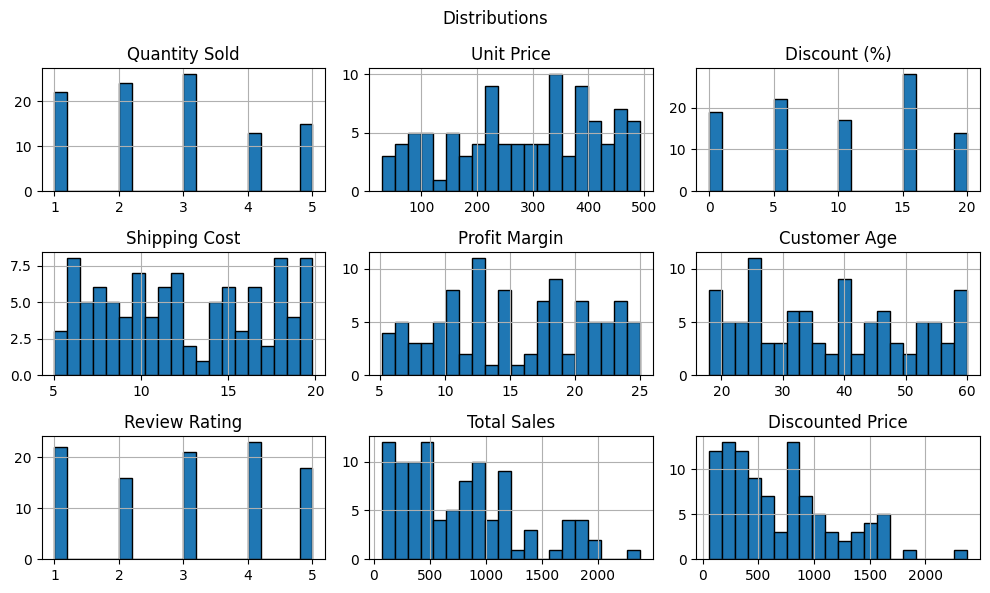

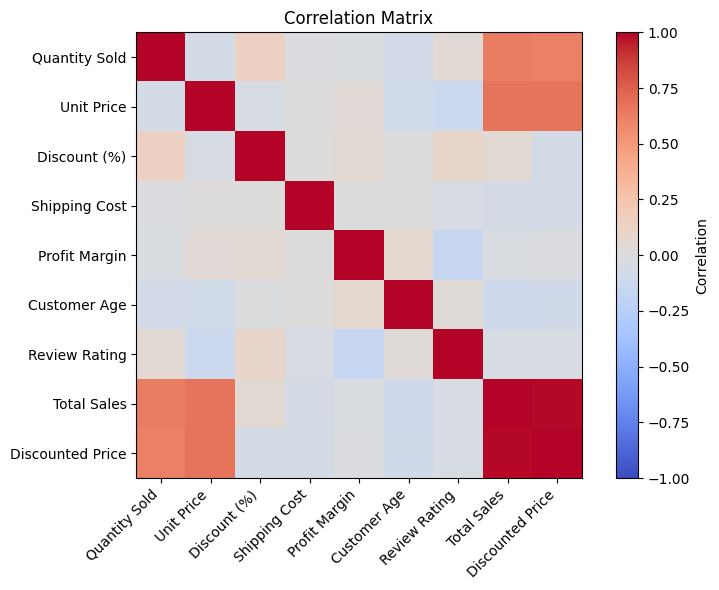

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("https://gist.githubusercontent.com/mathan-datagenie/bcf86165cefb4c1bf1401960c6661447/raw/ecommerce_sales_data.csv")


# Basic information
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)

# Fill missing values
num = df.select_dtypes(include=np.number).columns
cat = df.select_dtypes(exclude=np.number).columns

df[num] = df[num].fillna(df[num].median())
for c in cat:
    df[c] = df[c].fillna(df[c].mode()[0])

# Summary statistics
print("\nSummary Statistics:\n", df.describe())

# Distribution plots
df[num].hist(figsize=(10, 6), bins=20, edgecolor="black")
plt.suptitle("Distributions")
plt.tight_layout()
plt.show()

# Correlation matrix
corr = df[num].corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(num)), num, rotation=45, ha="right")
plt.yticks(range(len(num)), num)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()